# Phase 1 · 01 · Data overview

**Goal:** check that we have exactly the data the paper published, and describe it as a machine learning problem before touching anything.

**What this notebook shows**
- How we prove our input files are byte-for-byte the published ones (checksums).
- What one row and one column of the data mean.
- The three things every classifier needs: features, a label, and, for this dataset, a group.
- How sparse the features are, which explains the filtering step in notebook 03.

## Setup

Imports, paths and one small helper for figures. Every path is built from the project root, so the notebook works no matter which folder Jupyter was started from.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import pandas as pd
from IPython.display import Markdown, display

In [2]:
def find_project_root() -> Path:
    """Walk up from the current folder until we find the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("Could not find the project root (no requirements.txt above this folder).")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
RAW = PROJECT_ROOT / "data" / "raw"
FIGURES = PROJECT_ROOT / "results" / "figures"
NOTEBOOK_PREFIX = "p1_01"
print(PROJECT_ROOT)

D:\Projects\University\graduation_thesis


`show_figure` saves every figure to `results/figures/` and prints a caption under it. The caption is built from the numbers we computed, so it can never go out of date when the data changes.

In [3]:
figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{NOTEBOOK_PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))

## 1. Are these the published files?

An MD5 checksum is a short fingerprint of a file's bytes. If even one byte differs, the fingerprint is completely different. Zenodo publishes the fingerprint of each file, so comparing ours with theirs proves we start from exactly the same data as the paper.

The files are not downloaded by this notebook. Put them in `data/raw/` first (see the README).

In [4]:
EXPECTED_MD5 = {
    "Relab.all.samples.tsv": "cca9b0b616c721c5655ec1ba8825e260",
    "Metadata.all.samples.tsv": "e87644359858f853da198bce3e21b7de",
}


def md5_of(path: Path) -> str:
    return hashlib.md5(path.read_bytes()).hexdigest()


for file_name, expected in EXPECTED_MD5.items():
    path = RAW / file_name
    if not path.exists():
        raise FileNotFoundError(f"{path} is missing. Download it from https://zenodo.org/records/20310630 into data/raw/.")
    actual = md5_of(path)
    if actual != expected:
        raise ValueError(f"{file_name} is not the published file (MD5 {actual}, expected {expected}).")
    print(f"{file_name}: OK ({actual})")

Relab.all.samples.tsv: OK (cca9b0b616c721c5655ec1ba8825e260)
Metadata.all.samples.tsv: OK (e87644359858f853da198bce3e21b7de)


## 2. Load the two tables

- **Metadata:** one row per sample (one stool sample from one person), with facts about it: diagnosis, study, country, sequencing method.
- **Relab** (relative abundance): for each sample, the share of each bacterial genus in that sample. A genus is a group of closely related bacteria. Each sample's shares add up to 1.

Relab is stored the other way round, with genera as rows and samples as columns. Machine learning libraries expect one row per sample, so we transpose it. We also put both tables in the same row order, because a classifier pairs row *i* of the features with row *i* of the labels. A silent mismatch would pair a person's bacteria with someone else's diagnosis.

In [5]:
def load_raw_tables(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return (metadata, relab), both indexed by Sample_ID and in the same row order."""
    raw = root / "data" / "raw"
    metadata = pd.read_csv(raw / "Metadata.all.samples.tsv", sep="\t", index_col="Sample_ID", dtype={"Sample_ID": str})
    genus_by_sample = pd.read_csv(raw / "Relab.all.samples.tsv", sep="\t", index_col=0)
    relab = genus_by_sample.T
    if set(relab.index) != set(metadata.index):
        raise ValueError("The two tables do not contain the same samples.")
    relab = relab.loc[metadata.index]
    return metadata, relab


metadata, relab = load_raw_tables(PROJECT_ROOT)
print("metadata:", metadata.shape, "  relab:", relab.shape)

metadata: (8330, 25)   relab: (8330, 3804)


A peek at five samples and the five genera present in the most samples. Every row of the full table sums to 1.

In [6]:
most_common_genera = (relab > 0).mean().sort_values(ascending=False).index[:5]
relab[most_common_genera].head().round(4)

,unassigned,Bacteroides,Blautia_A,Phocaeicola,Enterocloster
Sample_ID,,,,,
SRR15884926,0.2424,0.0001,0.0039,0.0004,0.0000
SRR15884925,0.4652,0.0019,0.0298,0.0407,0.0040
SRR15884814,0.3123,0.0360,0.0091,0.0010,0.0553
SRR15884703,0.4179,0.0009,0.0165,0.0001,0.0004
SRR15884592,0.4396,0.0063,0.0119,0.0009,0.0003


## 3. The data as a machine learning problem

| ML term | In this dataset |
|---|---|
| sample (row) | one stool sample |
| feature (column) | one genus, its relative abundance in the sample |
| label | `Condition`: does the person have colorectal cancer (CRC) or not (CTR, control)? |
| group | `Cohort`: which of the 27 published studies the sample comes from |

The group is the unusual part. Each study collected and sequenced its samples in its own way, and those differences are much larger than the cancer signal. A model can learn "samples from study X look like this" instead of "cancer looks like this". Every evaluation in this project therefore keeps a study's samples together, which is what the paper does too.

In [7]:
pd.Series({
    "samples (rows)": relab.shape[0],
    "features: genera (columns)": relab.shape[1],
    "studies (Cohort)": metadata["Cohort"].nunique(),
    "countries": metadata["Country"].nunique(),
})

samples (rows)                8330
features: genera (columns)    3804
studies (Cohort)                27
countries                       15
dtype: int64

`Condition` has five values. Besides CRC and CTR there are three kinds of adenoma, which are non-cancerous growths that can become cancer later. The paper's classifier only separates CRC from CTR, so adenoma samples are left out from notebook 02 on.

In [8]:
metadata["Condition"].value_counts().rename("samples").to_frame()

,samples
Condition,
CRC,3516
CTR,3263
AdvAD,766
smallAD,590
AD,195


The samples were measured with two different sequencing methods (`Assay`): 16S, which reads one marker gene, and WGS, which reads all DNA in the sample. Both were converted to the same list of genera, which is what makes one combined table possible.

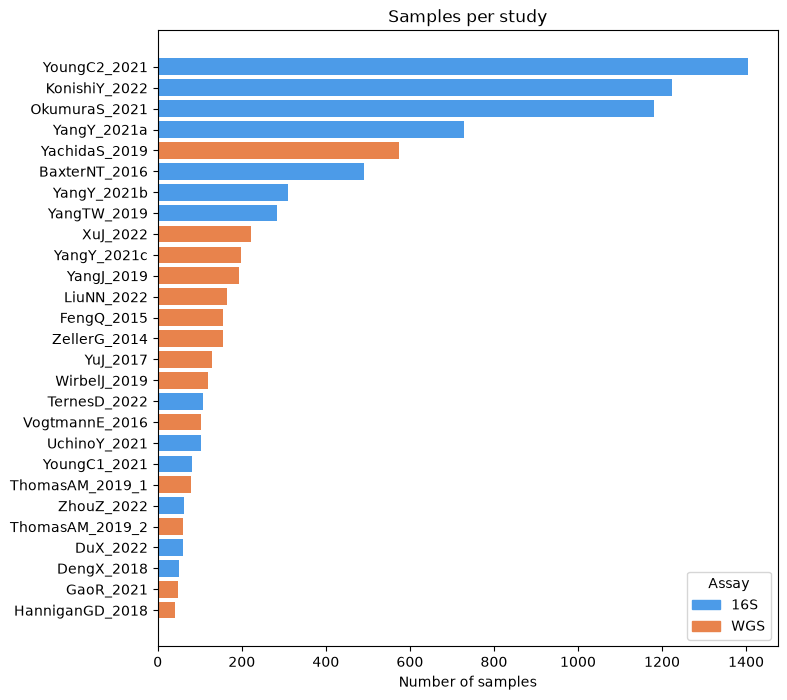

**Figure 1.** The 27 studies range from 42 samples (HanniganGD_2018) to 1,405 samples (YoungC2_2021), with a median of 155. 13 studies used 16S (6,085 samples) and 14 used WGS (2,245 samples).

In [9]:
cohort_table = (
    metadata.groupby("Cohort")
    .agg(samples=("Condition", "size"), assay=("Assay", "first"), assays_in_cohort=("Assay", "nunique"))
    .sort_values("samples")
)
assert (cohort_table["assays_in_cohort"] == 1).all(), "every cohort uses a single sequencing method"
cohort_table = cohort_table.drop(columns="assays_in_cohort")

fig, ax = plt.subplots(figsize=(8, 8))
assay_colors = {"16S": "#4C9BE8", "WGS": "#E8834C"}
ax.barh(cohort_table.index, cohort_table["samples"], color=cohort_table["assay"].map(assay_colors))
ax.legend(handles=[Patch(color=color, label=assay) for assay, color in assay_colors.items()], title="Assay")
ax.set_xlabel("Number of samples")
ax.set_title("Samples per study")

smallest, largest = cohort_table.iloc[0], cohort_table.iloc[-1]
per_assay = metadata.groupby("Assay").agg(samples=("Condition", "size"), cohorts=("Cohort", "nunique"))
show_figure(
    fig,
    "samples_per_cohort",
    f"The {len(cohort_table)} studies range from {smallest['samples']} samples ({smallest.name}) "
    f"to {largest['samples']:,} samples ({largest.name}), with a median of {cohort_table['samples'].median():.0f}. "
    f"{per_assay.loc['16S', 'cohorts']} studies used 16S ({per_assay.loc['16S', 'samples']:,} samples) and "
    f"{per_assay.loc['WGS', 'cohorts']} used WGS ({per_assay.loc['WGS', 'samples']:,} samples).",
)

## 4. How sparse are the features?

Most genera are absent from most samples, so most entries in the table are zero. The **prevalence** of a genus is the fraction of samples in which it is non-zero. A genus seen in almost no sample carries almost no information for a classifier and mostly adds noise, which is why the paper keeps only genera above 10% prevalence (notebook 03).

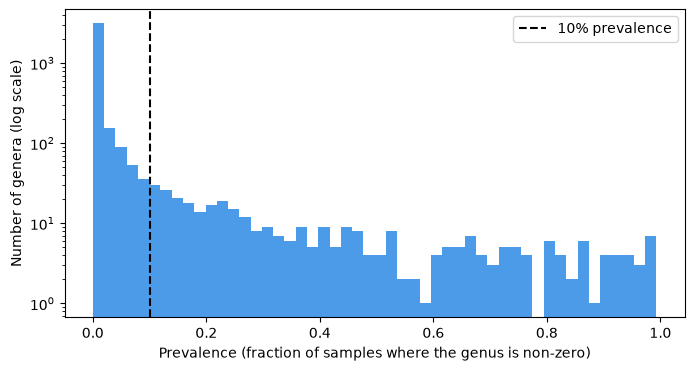

**Figure 2.** 95.8% of all entries in the 8,330 × 3,804 table are zero. Only 348 of the 3,804 genera are non-zero in more than 10% of samples (right of the dashed line), while 2,913 (77%) are non-zero in fewer than 1% of samples.

In [10]:
zero_share = (relab.to_numpy() == 0).mean()
prevalence = (relab > 0).mean()
above_10_percent = (prevalence > 0.10).sum()
below_1_percent = (prevalence < 0.01).sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(prevalence, bins=50, color="#4C9BE8")
ax.axvline(0.10, color="black", linestyle="--", label="10% prevalence")
ax.set_yscale("log")
ax.set_xlabel("Prevalence (fraction of samples where the genus is non-zero)")
ax.set_ylabel("Number of genera (log scale)")
ax.legend()

show_figure(
    fig,
    "genus_prevalence",
    f"{zero_share:.1%} of all entries in the {relab.shape[0]:,} × {relab.shape[1]:,} table are zero. "
    f"Only {above_10_percent} of the {relab.shape[1]:,} genera are non-zero in more than 10% of samples (right of the dashed line), "
    f"while {below_1_percent:,} ({below_1_percent / relab.shape[1]:.0%}) are non-zero in fewer than 1% of samples.",
)

## 5. Checks against the paper

These asserts stop the notebook if anything differs from what the paper and Zenodo report. `Sample_ID` is the row index, so the metadata shows 25 columns instead of the 26 in the file.

In [11]:
assert md5_of(RAW / "Relab.all.samples.tsv") == "cca9b0b616c721c5655ec1ba8825e260"
assert md5_of(RAW / "Metadata.all.samples.tsv") == "e87644359858f853da198bce3e21b7de"
assert metadata.shape == (8330, 25)
assert relab.shape == (8330, 3804)
assert metadata.index.equals(relab.index)
assert np.allclose(relab.sum(axis=1), 1.0)
assert metadata["Condition"].value_counts().to_dict() == {"CRC": 3516, "CTR": 3263, "AdvAD": 766, "smallAD": 590, "AD": 195}
assert metadata["Assay"].value_counts().to_dict() == {"16S": 6085, "WGS": 2245}
assert metadata["Cohort"].nunique() == 27
assert (metadata["Used_in_balanced_model"] == "Yes").sum() == 5966
print("All checks passed.")

All checks passed.


## What we learned

- Our two input files are byte-for-byte the files the paper published.
- The task is binary classification on a wide, sparse table: 8,330 samples, 3,804 genus features, and about 96% of all entries are zero.
- The label we need is CRC versus CTR (3,516 and 3,263 samples). The 1,551 adenoma samples are not part of this classifier.
- Samples come in 27 groups (studies) of very different sizes, from 42 to 1,405 samples. Evaluation has to keep each study together.
- Only 348 genera are present in more than 10% of samples, one of them being the `unassigned` row. Removing it leaves 347, the number the paper reports. Notebook 03 checks this properly.